# [5] train / val / test 나눠서 진짜 실력 확인하기

지금까지는 **A040 선수 사진 하나로 (1) 제일 좋은 epoch를 고르고 (2) 점수도 매겼어요.**
시험 문제를 미리 보고 답을 고른 셈이라, 점수(ResNet 미세조정 0.95)가 실제보다 좋게 나왔을 수 있어요.

그래서 데이터를 세 개로 나눕니다.

| 이름 | 선수 | 장수 | 하는 일 |
|---|---|---|---|
| train | A035, A036, A037, A038, A039 | 837 | 학습 |
| val | B002 | 96 | Early Stopping: 제일 좋은 epoch 고르기 |
| **test** | **A040** | **264** | **마지막에 딱 한 번 채점** (학습·선택에 전혀 안 씀) |

test를 A040으로 둬서, 앞에서 나온 "A040 점수 0.95"와 바로 비교할 수 있어요.
같은 조건에서 **CNN + Dropout(4-a)** 과 **ResNet18 미세조정(4-b)** 을 다시 학습해서 test 점수를 비교합니다.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [2]:
from torchvision import models

VAL_PERSON = "B002"
TEST_PERSON = "A040"

def split_by_person(dataset):
    """파일 이름에 있는 선수 번호로 train / val / test 인덱스 나누기"""
    train_idx, val_idx, test_idx = [], [], []
    for i, (path, _) in enumerate(dataset.samples):
        name = os.path.basename(path)
        if TEST_PERSON in name:
            test_idx.append(i)
        elif VAL_PERSON in name:
            val_idx.append(i)
        else:
            train_idx.append(i)
    return train_idx, val_idx, test_idx

# 확인용: 나눈 결과 개수
tmp = datasets.ImageFolder("tk_crops")
classes = tmp.classes
tr, va, te = split_by_person(tmp)
print("클래스:", classes)
for name, idx in [("train", tr), ("val", va), ("test", te)]:
    counts = np.bincount([tmp.targets[i] for i in idx], minlength=3)
    print(f"{name:5s}: {len(idx):4d}장  (시작 {counts[0]} / 중간 {counts[1]} / 끝 {counts[2]})")

클래스: ['1_start', '2_middle', '3_end']
train:  837장  (시작 279 / 중간 279 / 끝 279)
val  :   96장  (시작 32 / 중간 32 / 끝 32)
test :  264장  (시작 88 / 중간 88 / 끝 88)


In [3]:
def make_loaders(train_tf, eval_tf):
    """train은 증강 transform, val/test는 증강 없는 transform"""
    train_ds = datasets.ImageFolder("tk_crops", transform=train_tf)
    eval_ds = datasets.ImageFolder("tk_crops", transform=eval_tf)
    tr, va, te = split_by_person(train_ds)
    train_loader = DataLoader(Subset(train_ds, tr), batch_size=32, shuffle=True)
    val_loader = DataLoader(Subset(eval_ds, va), batch_size=32, shuffle=False)
    test_loader = DataLoader(Subset(eval_ds, te), batch_size=32, shuffle=False)
    return train_loader, val_loader, test_loader

# CNN용 (64 x 64, 지금까지와 같음)
cnn_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
cnn_train, cnn_val, cnn_test = make_loaders(cnn_tf, cnn_tf)

# ResNet용 (224 x 224, ImageNet 정규화, train만 좌우 뒤집기)
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
res_train_tf = transforms.Compose([
    transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])
res_eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])
res_train, res_val, res_test = make_loaders(res_train_tf, res_eval_tf)

In [4]:
criterion = nn.CrossEntropyLoss()

def train_model(model, optimizer, train_loader, val_loader, save_path, max_epochs=50, patience=5):
    """학습 + Early Stopping
    - val loss가 좋아질 때마다 모델을 파일(save_path)로 저장
    - patience번 연속으로 안 좋아지면 학습을 멈춤
    - 끝나면 제일 좋았던 모델을 다시 불러옴
    """
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_loss = float("inf")    # 지금까지 제일 낮은 val loss (처음엔 무한대)
    wait = 0                    # 몇 번 연속으로 안 좋아졌는지

    for epoch in range(max_epochs):
        # ----- 학습 -----
        model.train()
        total_loss, correct, total = 0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
        train_loss, train_acc = total_loss / total, correct / total

        # ----- 검증 -----
        model.eval()
        total_loss, correct, total = 0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                total_loss += criterion(outputs, labels).item() * labels.size(0)
                correct += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)
        val_loss, val_acc = total_loss / total, correct / total

        history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
        msg = f"Epoch {epoch + 1:2d} | train loss {train_loss:.4f} acc {train_acc:.4f} | val loss {val_loss:.4f} acc {val_acc:.4f}"

        # ----- Early Stopping -----
        if val_loss < best_loss:
            best_loss = val_loss
            wait = 0
            torch.save(model.state_dict(), save_path)     # 제일 좋은 모델 저장
            msg += "  ← best 저장"
        else:
            wait += 1
            msg += f"  (좋아지지 않음 {wait}/{patience})"
        print(msg)
        if wait >= patience:
            print(f"→ {patience}번 연속 val loss가 좋아지지 않아서 {epoch + 1} epoch에서 멈춤")
            break

    model.load_state_dict(torch.load(save_path))          # 제일 좋았던 모델로 되돌리기
    return history

In [5]:
def evaluate(model, val_loader, n_classes=3):
    """정확도와 혼동행렬 (행 = 정답, 열 = 예측)"""
    model.eval()
    cm = np.zeros((n_classes, n_classes), dtype=int)
    with torch.no_grad():
        for images, labels in val_loader:
            preds = model(images.to(device)).argmax(1).cpu()
            for t, p in zip(labels, preds):
                cm[t, p] += 1
    acc = np.trace(cm) / cm.sum()       # 대각선 합 / 전체
    return acc, cm

def plot_cm(cm, classes, title):
    plt.imshow(cm, cmap="Blues")
    plt.xticks(range(len(classes)), classes); plt.yticks(range(len(classes)), classes)
    plt.xlabel("예측"); plt.ylabel("정답"); plt.title(title)
    for i in range(len(classes)):
        for j in range(len(classes)):
            plt.text(j, i, cm[i, j], ha="center", va="center")

## 모델 2개 (4-a, 4-b와 같은 구조)

In [6]:
class CNN(nn.Module):
    def __init__(self, dropout=0.5):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU()
        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(128, 3)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        x = x.view(x.size(0), -1)
        x = self.dropout(self.relu(self.fc1(x)))
        return self.fc2(x)


def build_resnet_finetune():
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    model.fc = nn.Linear(model.fc.in_features, 3)
    model = model.to(device)
    backbone = [p for name, p in model.named_parameters() if not name.startswith("fc")]
    optimizer = optim.Adam([
        {"params": backbone, "lr": 0.0001},
        {"params": model.fc.parameters(), "lr": 0.001},
    ])
    return model, optimizer

## 1) CNN + Dropout 학습 (val = B002로 Early Stopping)

In [7]:
results = {}
torch.manual_seed(42)
cnn = CNN(dropout=0.5).to(device)
results["CNN+Dropout"] = train_model(cnn, optim.Adam(cnn.parameters(), lr=0.001),
                                     cnn_train, cnn_val, "best5_cnn.pth")

Epoch  1 | train loss 1.1043 acc 0.3692 | val loss 1.0858 acc 0.3438  ← best 저장
Epoch  2 | train loss 0.9443 acc 0.5125 | val loss 0.9988 acc 0.5625  ← best 저장
Epoch  3 | train loss 0.7609 acc 0.6511 | val loss 1.0518 acc 0.5104  (좋아지지 않음 1/5)
Epoch  4 | train loss 0.6486 acc 0.7240 | val loss 1.3488 acc 0.4583  (좋아지지 않음 2/5)
Epoch  5 | train loss 0.5511 acc 0.7706 | val loss 1.4744 acc 0.5104  (좋아지지 않음 3/5)
Epoch  6 | train loss 0.4540 acc 0.8053 | val loss 1.0652 acc 0.5729  (좋아지지 않음 4/5)
Epoch  7 | train loss 0.3834 acc 0.8554 | val loss 1.4009 acc 0.5417  (좋아지지 않음 5/5)
→ 5번 연속 val loss가 좋아지지 않아서 7 epoch에서 멈춤


## 2) ResNet18 미세조정 학습 (val = B002로 Early Stopping)

In [8]:
torch.manual_seed(42)
resnet, res_opt = build_resnet_finetune()
results["ResNet18 미세조정"] = train_model(resnet, res_opt, res_train, res_val,
                                       "best5_resnet.pth", max_epochs=30)

Epoch  1 | train loss 0.5458 acc 0.7563 | val loss 1.2127 acc 0.6042  ← best 저장
Epoch  2 | train loss 0.1170 acc 0.9654 | val loss 1.1231 acc 0.6667  ← best 저장
Epoch  3 | train loss 0.0643 acc 0.9797 | val loss 0.8668 acc 0.6771  ← best 저장
Epoch  4 | train loss 0.0681 acc 0.9725 | val loss 1.0656 acc 0.6354  (좋아지지 않음 1/5)
Epoch  5 | train loss 0.0750 acc 0.9761 | val loss 1.9427 acc 0.6562  (좋아지지 않음 2/5)
Epoch  6 | train loss 0.0345 acc 0.9892 | val loss 1.1119 acc 0.6875  (좋아지지 않음 3/5)
Epoch  7 | train loss 0.0209 acc 0.9916 | val loss 1.2438 acc 0.6667  (좋아지지 않음 4/5)
Epoch  8 | train loss 0.0271 acc 0.9928 | val loss 1.9036 acc 0.6042  (좋아지지 않음 5/5)
→ 5번 연속 val loss가 좋아지지 않아서 8 epoch에서 멈춤


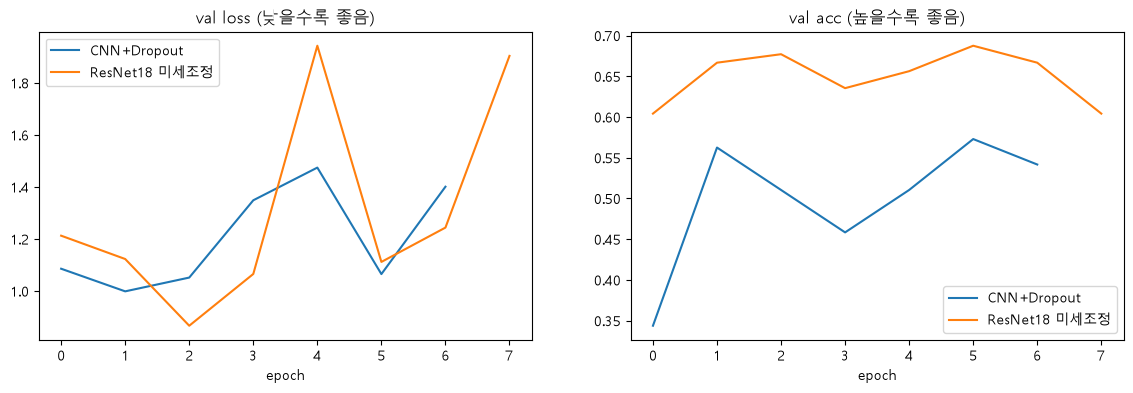

In [9]:
plt.figure(figsize=(14, 4))
plt.subplot(1, 2, 1)
for name, h in results.items():
    plt.plot(h["val_loss"], label=name)
plt.title("val loss (낮을수록 좋음)"); plt.xlabel("epoch"); plt.legend()
plt.subplot(1, 2, 2)
for name, h in results.items():
    plt.plot(h["val_acc"], label=name)
plt.title("val acc (높을수록 좋음)"); plt.xlabel("epoch"); plt.legend()
plt.show()

## 3) test(A040) 채점 — 여기서 처음으로 A040을 봄
학습도, epoch 고르기도 끝났으니 이제 딱 한 번만 채점합니다.

모델               | val(B002) acc | test(A040) acc | 예전 A040 점수 (4-a, 4-b)
CNN+Dropout      | 0.5625        | 0.5644         | 0.8598
ResNet18 미세조정    | 0.6771        | 0.8977         | 0.9545


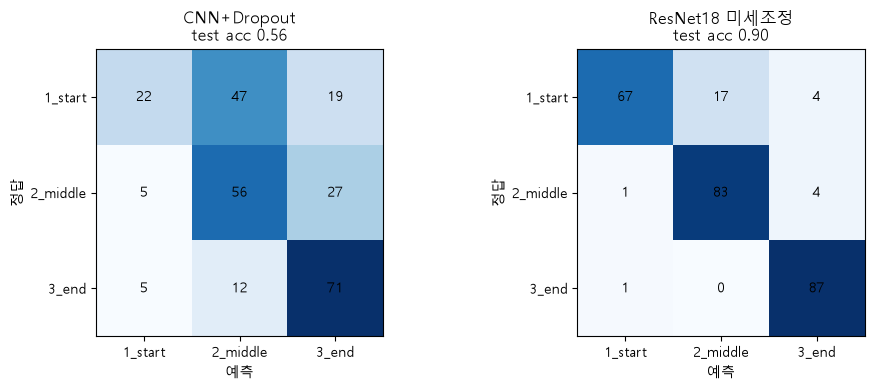

In [10]:
runs = [("CNN+Dropout", cnn, cnn_val, cnn_test), ("ResNet18 미세조정", resnet, res_val, res_test)]
before = {"CNN+Dropout": 0.8598, "ResNet18 미세조정": 0.9545}     # 앞 노트북에서 A040으로 고르고 채점했던 점수

print(f"{'모델':16s} | val(B002) acc | test(A040) acc | 예전 A040 점수 (4-a, 4-b)")
plt.figure(figsize=(10, 4))
for k, (name, m, vl, tl) in enumerate(runs):
    val_acc, _ = evaluate(m, vl)
    test_acc, cm = evaluate(m, tl)
    print(f"{name:16s} | {val_acc:.4f}        | {test_acc:.4f}         | {before[name]:.4f}")
    plt.subplot(1, 2, k + 1)
    plot_cm(cm, classes, f"{name}\ntest acc {test_acc:.2f}")
plt.tight_layout(); plt.show()

In [11]:
# ResNet이 test에서 틀린 사진만 모아 보기
mean, std = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)
wrong = []
resnet.eval()
with torch.no_grad():
    for images, labels in res_test:
        probs = torch.softmax(resnet(images.to(device)), dim=1).cpu()
        preds = probs.argmax(1)
        for i in range(len(labels)):
            if preds[i] != labels[i]:
                wrong.append((images[i], labels[i].item(), preds[i].item(), probs[i, preds[i]].item()))

print("test에서 틀린 개수:", len(wrong))
n = min(len(wrong), 10)
if n > 0:
    plt.figure(figsize=(1.6 * n, 3))
    for k in range(n):
        img, t, p, conf = wrong[k]
        plt.subplot(1, n, k + 1)
        plt.imshow((img * std + mean).permute(1, 2, 0).clamp(0, 1))
        plt.title(f"정답 {classes[t]}\n예측 {classes[p]}\n{conf:.0%}", fontsize=8, color="red")
        plt.axis("off")
    plt.show()

test에서 틀린 개수: 27


## 결과 읽는 법
- **test acc가 예전 A040 점수보다 조금 낮다** → 예전 점수가 살짝 부풀려져 있었다는 뜻 (정상이에요)
- **test acc가 비슷하다** → 예전 점수도 믿을 만했다는 뜻
- **val(B002)은 96장뿐**이라 epoch 고르기가 조금 거칠 수 있어요. 1장 = 약 1%

## 생각해볼 것
1. test 점수와 val 점수 중 보고서·발표에 써야 하는 숫자는 어느 쪽일까?
2. test를 보고 나서 "점수가 낮으니 lr을 바꿔서 다시 해볼까?" 하면 무슨 문제가 생길까?
3. 선수가 7명뿐인데, test를 한 명만 쓰지 않고 더 믿을 만하게 평가하려면? (힌트: 교차검증)